# Home Credit Default Risk: first data check

### Purpose

- How big is the data, 
- What is the default rate, 
- How bad is the missing data, which tables join, which columns are sensitive, and what a simple baseline scores

### Scope
- Inspection and one tiny baseline only. This is not the project pipeline (Week 5) and not the final model


**Refrences Dataset:** https://www.kaggle.com/competitions/home-credit-default-risk/data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

DATA_DIR = Path.home() / "Desktop" / "home_credit_default_risk"
RANDOM_STATE = 42

## 1. Load the main table

In [2]:
train = pd.read_csv(DATA_DIR / "application_train.csv")
n_rows, n_cols = train.shape
print("Rows, columns:", train.shape)



Rows, columns: (307511, 122)


## 2. Target and default rate
`TARGET = 1` marks a client with payment difficulties. This is the plan's target variable.

In [3]:
counts = train["TARGET"].value_counts().sort_index()
default_rate = train["TARGET"].mean()
print(counts.to_string())
print(f"Default rate (TARGET = 1): {default_rate:.2%}")
naive_brier = default_rate * (1 - default_rate)
print(f"Naive baseline (always predict {default_rate:.3f}): ROC-AUC 0.5, Brier {naive_brier:.4f}")

TARGET
0    282686
1     24825
Default rate (TARGET = 1): 8.07%
Naive baseline (always predict 0.081): ROC-AUC 0.5, Brier 0.0742


## 3. Missing values
Feeds the audit rating for **completeness**.

Columns with any missing value: 67 of 122
Columns with more than 50% missing: 41


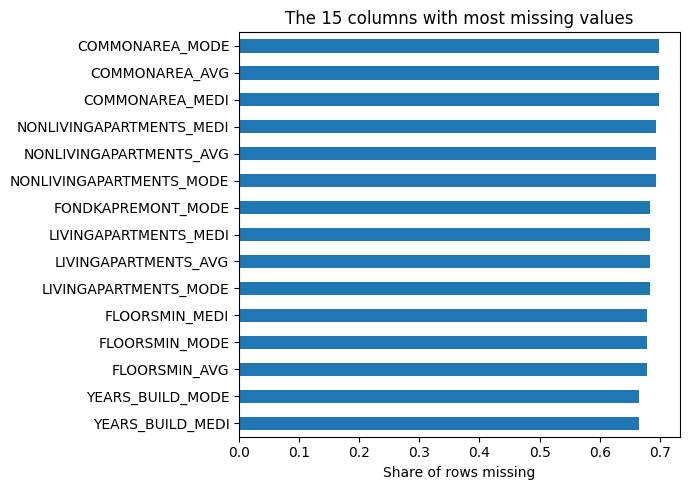

In [4]:
miss = train.isna().mean().sort_values(ascending=False)
n_any, n_half = int((miss > 0).sum()), int((miss > 0.5).sum())
print(f"Columns with any missing value: {n_any} of {train.shape[1]}")
print(f"Columns with more than 50% missing: {n_half}")
ax = miss.head(15).sort_values().plot.barh(figsize=(7, 5))
ax.set_xlabel("Share of rows missing")
ax.set_title("The 15 columns with most missing values")
plt.tight_layout(); plt.show()

## 4. Table inventory and join keys
Row counts are line counts (fast, approximate if text fields contain line breaks). Feeds the **data availability** rating and the MVP table choice.

In [5]:
def count_lines(path):
    with open(path, "rb") as f:
        return sum(buf.count(b"\n") for buf in iter(lambda: f.read(1 << 20), b"")) - 1

def read_header(path):
    try:
        return pd.read_csv(path, nrows=0).columns
    except UnicodeDecodeError:
        return pd.read_csv(path, nrows=0, encoding="latin-1").columns

rows = []
for p in sorted(DATA_DIR.glob("*.csv")):
    header = read_header(p)
    keys = [k for k in ("SK_ID_CURR", "SK_ID_BUREAU", "SK_ID_PREV") if k in header]
    rows.append({"file": p.name, "rows": count_lines(p), "columns": len(header),
                 "join keys": ", ".join(keys), "size MB": round(p.stat().st_size / 1e6, 1)})
inventory = pd.DataFrame(rows)
display(inventory)

,file,rows,columns,join keys,size MB
0,HomeCredit_columns_description.csv,219,5,,0.0
1,POS_CASH_balance.csv,10001358,8,"SK_ID_CURR, SK_ID_PREV",392.7
2,application_test.csv,48744,121,SK_ID_CURR,26.6
3,application_train.csv,307511,122,SK_ID_CURR,166.1
4,bureau.csv,1716428,17,"SK_ID_CURR, SK_ID_BUREAU",170.0
5,bureau_balance.csv,27299925,3,SK_ID_BUREAU,375.6
6,credit_card_balance.csv,3840312,23,"SK_ID_CURR, SK_ID_PREV",424.6
7,installments_payments.csv,13605401,8,"SK_ID_CURR, SK_ID_PREV",723.1
8,previous_application.csv,1670214,37,"SK_ID_CURR, SK_ID_PREV",405.0
9,sample_submission.csv,48744,2,SK_ID_CURR,0.5


## 5. Sensitive attributes and group sizes
Feeds the **legal / ethical** rating and the fairness check (success metric b). Age is derived from `DAYS_BIRTH` (days before the application, so negative).

In [6]:
sensitive = [c for c in ("CODE_GENDER", "DAYS_BIRTH", "NAME_FAMILY_STATUS", "NAME_EDUCATION_TYPE") if c in train]
print("Sensitive-type columns present:", sensitive)

train["AGE"] = -train["DAYS_BIRTH"] / 365.25
train["AGE_BAND"] = pd.cut(train["AGE"], [0, 30, 40, 50, 60, 120],
                           labels=["<30", "30-39", "40-49", "50-59", "60+"], right=False)
for col in ("CODE_GENDER", "AGE_BAND"):
    g = train.groupby(col, observed=True)["TARGET"].agg(applications="size", default_rate="mean")
    g["default_rate"] = (g["default_rate"] * 100).round(2)
    g = g.rename(columns={"default_rate": "default rate %"})
    display(g)

Sensitive-type columns present: ['CODE_GENDER', 'DAYS_BIRTH', 'NAME_FAMILY_STATUS', 'NAME_EDUCATION_TYPE']


,applications,default rate %
CODE_GENDER,,
F,202448,7.00
M,105059,10.14
XNA,4,0.00


,applications,default rate %
AGE_BAND,,
<30,45186,11.44
30-39,82331,9.59
40-49,76599,7.64
50-59,68094,6.12
60+,35301,4.92


## 6. Time fields

- Supports the split choice: if every `DAYS_*` column is relative to the application date, there are no absolute dates, so walk-forward validation is not possible and a stratified split is the justified choice. Confirm against `HomeCredit_columns_description.csv`

In [7]:
days_cols = [c for c in train.columns if c.startswith("DAYS_")]
display(train[days_cols].agg(["min", "max"]).T)

if "DAYS_EMPLOYED" in train:
    top_val = train["DAYS_EMPLOYED"].max()
    n_top = int((train["DAYS_EMPLOYED"] == top_val).sum())
    print(f"DAYS_EMPLOYED: the largest value {top_val} appears {n_top} times "
          f"({n_top / len(train):.1%} of rows). Check whether it is a placeholder.")

,min,max
DAYS_BIRTH,-25229.0,-7489.0
DAYS_EMPLOYED,-17912.0,365243.0
DAYS_REGISTRATION,-24672.0,0.0
DAYS_ID_PUBLISH,-7197.0,0.0
DAYS_LAST_PHONE_CHANGE,-4292.0,0.0


DAYS_EMPLOYED: the largest value 365243 appears 55374 times (18.0% of rows). Check whether it is a placeholder.


## 7. One tiny baseline
Regularised logistic regression on a few numeric features, stratified 80/20 split, median imputation. It excludes gender and age on purpose. It exists to give the plan a real reference score, not to be the final model.

In [8]:
FEATURES = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AMT_INCOME_TOTAL", "AMT_CREDIT",
                        "AMT_ANNUITY", "AMT_GOODS_PRICE", "DAYS_EMPLOYED", "DAYS_ID_PUBLISH", "CNT_CHILDREN"]
            if c in train]
X = train[FEATURES].copy()
if "DAYS_EMPLOYED" in X:
    top_val = X["DAYS_EMPLOYED"].max()
    if (X["DAYS_EMPLOYED"] == top_val).mean() > 0.05:   # a large block at one value = placeholder (see section 6)
        X["DAYS_EMPLOYED"] = X["DAYS_EMPLOYED"].replace(top_val, np.nan)
y = train["TARGET"]

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LogisticRegression(max_iter=1000))
model.fit(X_tr, y_tr)
p_val = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, p_val)
brier = brier_score_loss(y_val, p_val)
print(f"Features used ({len(FEATURES)}): {FEATURES}")
print(f"Validation ROC-AUC: {auc:.3f}   (naive reference 0.5)")
print(f"Validation Brier:   {brier:.4f}   (naive reference {naive_brier:.4f})")

Features used (10): ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_EMPLOYED', 'DAYS_ID_PUBLISH', 'CNT_CHILDREN']
Validation ROC-AUC: 0.729   (naive reference 0.5)
Validation Brier:   0.0693   (naive reference 0.0742)


/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/sklearn/linear_model/_linea

## 8. Fairness preview (first look only)
Illustration: approve the 80% of validation applicants with the lowest predicted risk, then compare groups. The 80% operating point is arbitrary and only shows what the plan's success metric (b) would measure. Groups under 100 applicants are ignored in the gap.

In [9]:
val = train.loc[X_val.index, ["CODE_GENDER", "AGE_BAND", "TARGET"]].copy()
threshold = np.quantile(p_val, 0.80)
val["approved"] = p_val <= threshold

gaps = {}
for col in ("CODE_GENDER", "AGE_BAND"):
    g = val.groupby(col, observed=True).agg(
        applicants=("approved", "size"),
        approval_rate=("approved", "mean"))
    g["defaulters approved %"] = val[val["TARGET"] == 1].groupby(col, observed=True)["approved"].mean() * 100
    g["approval_rate"] = (g["approval_rate"] * 100).round(1)
    g = g.rename(columns={"approval_rate": "approval rate %"}).round(1)
    display(g)
    big = g[g["applicants"] >= 100]
    gaps[col] = big["approval rate %"].max() - big["approval rate %"].min()
    print(f"Approval-rate gap across {col}: {gaps[col]:.1f} percentage points\n")

,applicants,approval rate %,defaulters approved %
CODE_GENDER,,,
F,40561,81.8,54.2
M,20940,76.6,49.2
XNA,2,50.0,NaN


Approval-rate gap across CODE_GENDER: 5.2 percentage points



,applicants,approval rate %,defaulters approved %
AGE_BAND,,,
<30,8905,57.7,33.5
30-39,16487,76.6,47.8
40-49,15303,84.5,57.1
50-59,13617,88.5,66.0
60+,7191,89.8,73.1


Approval-rate gap across AGE_BAND: 32.1 percentage points



## 9. Numbers for the plan
Copy these into the data audit and the problem statement.

In [10]:
print("DATA CHECK SUMMARY")
print(f"- application_train: {n_rows:,} rows, {n_cols} columns")
print(f"- default rate: {default_rate:.2%}")
print(f"- columns with missing values: {n_any}; with more than 50% missing: {n_half}")
print(f"- CSV files found: {len(inventory)}; tables with SK_ID_CURR: "
      f"{int(inventory['join keys'].str.contains('SK_ID_CURR').sum())}")
print(f"- baseline (logistic regression, {len(FEATURES)} features): ROC-AUC {auc:.3f}, Brier {brier:.4f}")
print(f"- naive reference: ROC-AUC 0.5, Brier {naive_brier:.4f}")
print(f"- approval-rate gap (80% approved): gender {gaps['CODE_GENDER']:.1f} pp, age band {gaps['AGE_BAND']:.1f} pp")

DATA CHECK SUMMARY
- application_train: 307,511 rows, 122 columns
- default rate: 8.07%
- columns with missing values: 67; with more than 50% missing: 41
- CSV files found: 10; tables with SK_ID_CURR: 8
- baseline (logistic regression, 10 features): ROC-AUC 0.729, Brier 0.0693
- naive reference: ROC-AUC 0.5, Brier 0.0742
- approval-rate gap (80% approved): gender 5.2 pp, age band 32.1 pp
